In [1]:
# Hamza Alsihati
# 2230006810

import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

In [2]:
dataframe = pd.read_csv("dataset/Lab_11_QnA_Dataset.csv")
print("Number of questions:", len(dataframe))
print("Number of answer groups:", dataframe["answer_id"].nunique())

Number of questions: 168
Number of answer groups: 12


In [3]:
dataframe["question"] = dataframe["question"].str.lower()
tokenizer = Tokenizer()
tokenizer.fit_on_texts(dataframe["question"])

X = torch.tensor(pad_sequences(tokenizer.texts_to_sequences(dataframe["question"]), padding="post"), dtype=torch.long)
y = torch.tensor(dataframe["answer_id"].tolist(), dtype=torch.long)
print(X.shape, y.shape)

torch.Size([168, 11]) torch.Size([168])


In [4]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16)
        self.rnn = nn.RNN(16, 32, batch_first=True)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, dataframe["answer_id"].nunique())

    def forward(self, x):
        x, _ = self.rnn(self.emb(x))
        weights = torch.softmax(self.att(x), dim=1)
        return self.fc((x * weights).sum(1)), weights.squeeze(-1)

torch.manual_seed(42)
model = RNN()

In [5]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(50):
    loss = nn.functional.cross_entropy(model(X)[0], y)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

print("Final loss:", loss.item())

Final loss: 0.09667359292507172


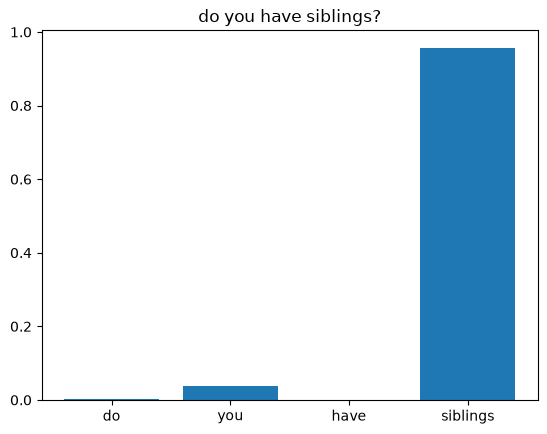

Highest attention: siblings


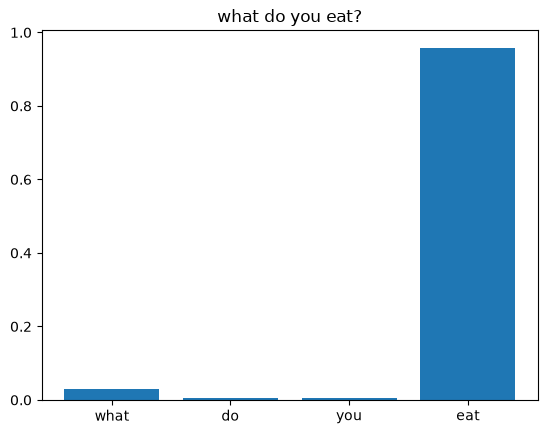

Highest attention: eat


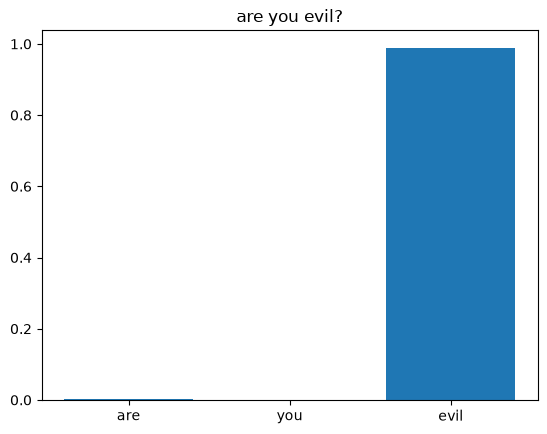

Highest attention: evil


In [6]:
def show_attention(i):
    words = [tokenizer.index_word[t] for t in X[i].tolist() if t > 0]
    with torch.no_grad():
        weights = model(X[i:i + 1])[1][0, :len(words)].tolist()
    plt.bar(words, weights)
    plt.title(dataframe["question"][i])
    plt.show()
    print("Highest attention:", words[weights.index(max(weights))])

for i in [89, 108, 149]:
    show_attention(i)

# Highest attention: siblings, eat and evil
# Yes, these are the key words that decide the answer, while words like do, you and have get almost no attention

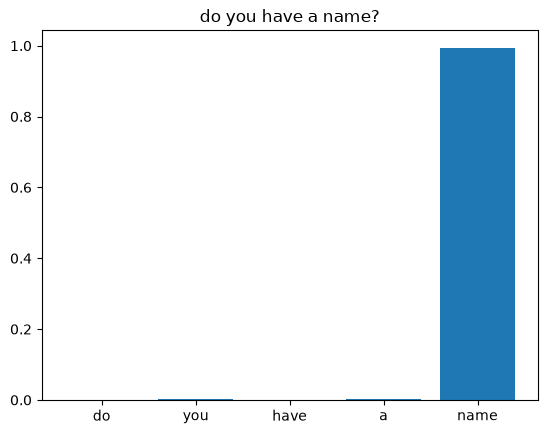

Highest attention: name


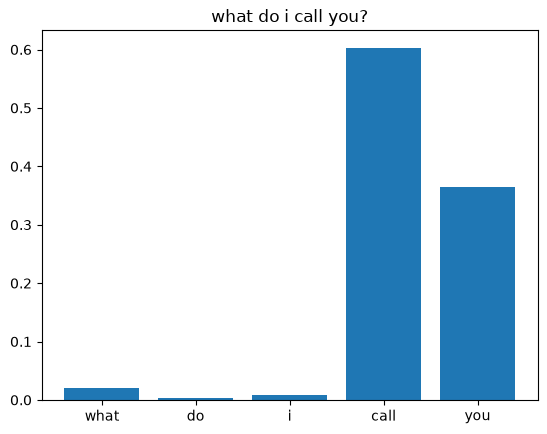

Highest attention: call


In [ ]:
for i in [115, 119]:
    show_attention(i)

# The model focuses on different words, but each one is the word that carries the meaning of its question
# This suggests attention does not look for fixed words, it learns which word in each question is most useful for choosing the answer